In [32]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [33]:
dates = pd.date_range(
    start = '1973-01-01',
    periods = 600,
    freq = 'MS'
)
dates

DatetimeIndex(['1973-01-01', '1973-02-01', '1973-03-01', '1973-04-01',
               '1973-05-01', '1973-06-01', '1973-07-01', '1973-08-01',
               '1973-09-01', '1973-10-01',
               ...
               '2022-03-01', '2022-04-01', '2022-05-01', '2022-06-01',
               '2022-07-01', '2022-08-01', '2022-09-01', '2022-10-01',
               '2022-11-01', '2022-12-01'],
              dtype='datetime64[us]', length=600, freq='MS')

In [34]:
dates.shape

(600,)

In [35]:
np.random.seed(42)
t=np.linspace(600,6000,600)

In [36]:
t.shape

(600,)

In [37]:
data = np.random.randint(-300,500,600)

In [38]:
data.shape

(600,)

In [39]:
sales = data+t

In [40]:
sales.shape

(600,)

In [41]:
df=pd.DataFrame({
    "date":dates,
    "sales":sales
})

In [42]:
df.shape

(600, 2)

In [43]:
df.head(5)

,date,sales
0,1973-01-01,402.000000
1,1973-02-01,744.015025
2,1973-03-01,588.030050
3,1973-04-01,433.045075
4,1973-05-01,407.060100


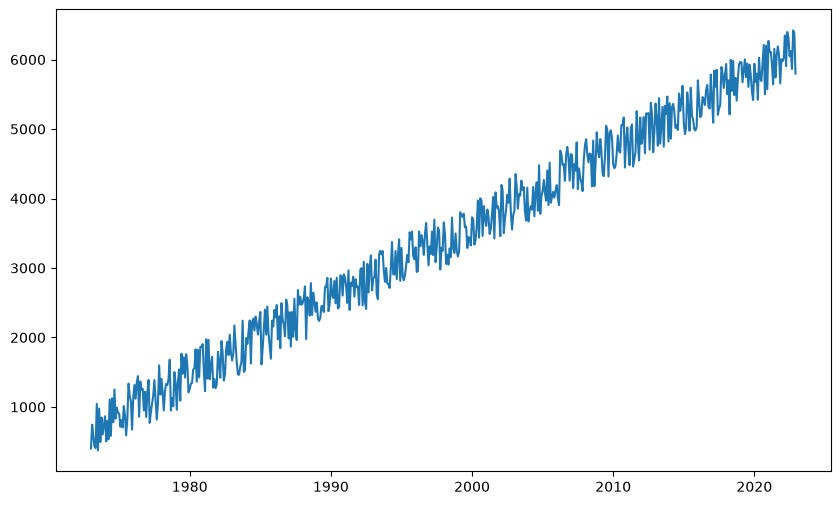

In [44]:
plt.figure(figsize=(10,6))
plt.plot(df["date"],df["sales"])
plt.show()

In [45]:
df["lag1"]=df["sales"].shift(1)
df["lag2"]=df["sales"].shift(2)
df["lag3"]=df["sales"].shift(3)

In [46]:
df.head()

,date,sales,lag1,lag2,lag3
0,1973-01-01,402.000000,NaN,NaN,NaN
1,1973-02-01,744.015025,402.000000,NaN,NaN
2,1973-03-01,588.030050,744.015025,402.000000,NaN
3,1973-04-01,433.045075,588.030050,744.015025,402.000000
4,1973-05-01,407.060100,433.045075,588.030050,744.015025


In [47]:
df=df.dropna()

In [48]:
df.head()

,date,sales,lag1,lag2,lag3
3,1973-04-01,433.045075,588.030050,744.015025,402.000000
4,1973-05-01,407.060100,433.045075,588.030050,744.015025
5,1973-06-01,1045.075125,407.060100,433.045075,588.030050
6,1973-07-01,374.090150,1045.075125,407.060100,433.045075
7,1973-08-01,977.105175,374.090150,1045.075125,407.060100


In [49]:
df=df.drop(columns=["date"])

In [50]:
# Divide into X and y
X=df.drop(columns=["sales"])
y=df["sales"]

In [51]:
from sklearn.linear_model import LinearRegression

In [52]:
split_index=int(len(X)*0.8)
split_index

477

In [53]:
X_train=X.iloc[:split_index]
X_test=X.iloc[split_index:]

In [54]:
X_train.shape,X_test.shape

((477, 3), (120, 3))

In [55]:
y_train=y.iloc[:split_index]
y_test=y.iloc[split_index:]

In [56]:
y_train.shape,y_test.shape

((477,), (120,))

In [57]:
re=LinearRegression()

In [58]:
re.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.31,0.33,0.35]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['lag1','lag2','lag3']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,54.66
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [59]:
y_pred=re.predict(X_test)

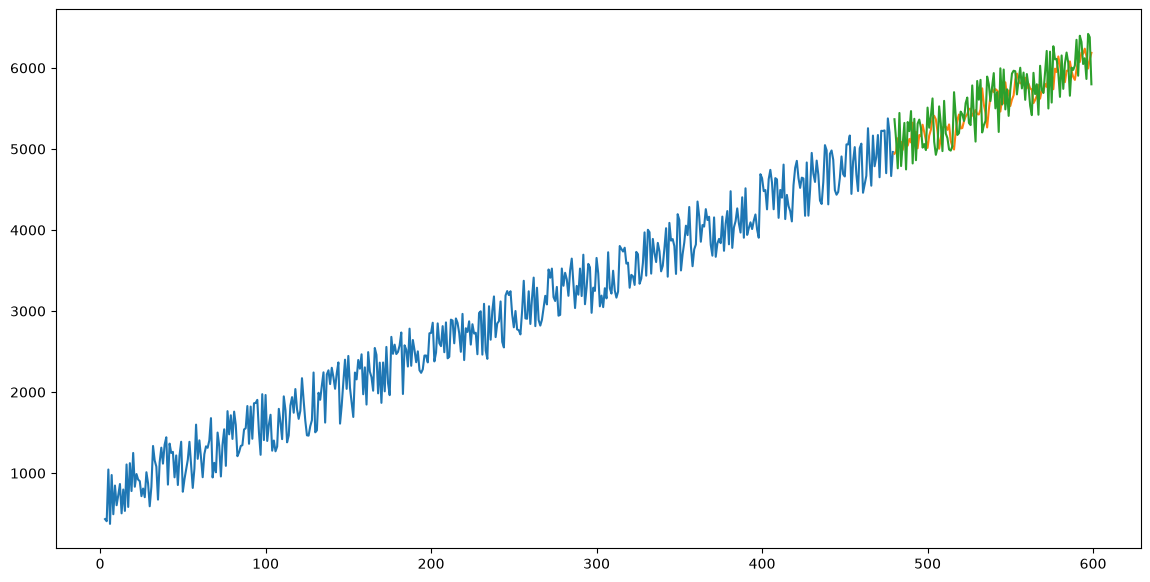

In [63]:
plt.figure(figsize=(14,7))

plt.plot(y_train)

plt.plot(y_test.index,y_pred)
plt.plot(y_test)
plt.show()

In [61]:
re.coef_

array([0.30888543, 0.32846757, 0.34996273])